# Тема 6. Кластеризация и снижение размерности

**Практическая работа выполнена в Jupyter Notebook.** Для набора Wine выполнены аудит данных, масштабирование, подбор и проверка устойчивости кластеризации, сравнение альтернативных алгоритмов, PCA/t-SNE и внешняя диагностика после открытия `target` в задании 10. Случайные процедуры фиксируются через `random_state=42` (или документированные seed в анализе устойчивости). Все модели до задания 10 обучаются только на `X`.

In [1]:
import sys, warnings, importlib.util
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import (
    pairwise_distances, silhouette_score, silhouette_samples,
    calinski_harabasz_score, davies_bouldin_score,
    adjusted_rand_score, normalized_mutual_info_score,
)
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from scipy.cluster.hierarchy import linkage as scipy_linkage, dendrogram
from IPython.display import display, Markdown

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)
print('Python:', sys.version.split()[0])
print('scikit-learn:', sklearn.__version__)

Python: 3.13.5
scikit-learn: 1.8.0


In [2]:
wine=load_wine(as_frame=True)
X=wine.data.copy()
y_hidden=wine.target.copy()  # НЕ ИСПОЛЬЗОВАТЬ ДО ЗАДАНИЯ 10
X.shape, X.head()

((178, 13),
    alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  \
 0    14.23        1.71  2.43               15.6      127.0           2.80        3.06                  0.28             2.29   
 1    13.20        1.78  2.14               11.2      100.0           2.65        2.76                  0.26             1.28   
 2    13.16        2.36  2.67               18.6      101.0           2.80        3.24                  0.30             2.81   
 3    14.37        1.95  2.50               16.8      113.0           3.85        3.49                  0.24             2.18   
 4    13.24        2.59  2.87               21.0      118.0           2.80        2.69                  0.39             1.82   
 
    color_intensity   hue  od280/od315_of_diluted_wines  proline  
 0             5.64  1.04                          3.92   1065.0  
 1             4.38  1.05                          3.40   1050.0  
 2         

## 1. Аудит и постановка

**Цель:** Сформулировать объект анализа, прикладную цель и риски.  
**Задание:** Вывести shape, типы, пропуски, описательные статистики, дубликаты. Составить data card: строка, признак, период, предполагаемое применение кластеров. Не анализировать target.  
**Ожидаемый результат:** Таблица аудита и 5–8 предложений постановки.

In [3]:
# 1. Аудит данных без использования target
print(f'Размер X: {X.shape[0]} наблюдений × {X.shape[1]} признаков')
print('\nТипы столбцов:')
display(X.dtypes.rename('dtype').to_frame())

summary = X.describe().T
summary['missing'] = X.isna().sum()
summary['n_unique'] = X.nunique()
summary['n_zeros'] = (X == 0).sum()
summary['IQR'] = summary['75%'] - summary['25%']
display(summary.round(3))

n_duplicates = int(X.duplicated().sum())
constant_features = X.columns[X.nunique() <= 1].tolist()
audit = pd.DataFrame({
    'Проверка': ['Число строк', 'Число признаков', 'Пропущенные значения',
                 'Полные дубликаты строк', 'Константные признаки'],
    'Результат': [len(X), X.shape[1], int(X.isna().sum().sum()),
                  n_duplicates, ', '.join(constant_features) if constant_features else 'нет']
})
display(audit)

# Data card: в описании учебного набора период сбора не указан.
data_card = pd.DataFrame([
    ['Строка', 'Один образец вина; отдельный образец — единица анализа'],
    ['Признаки', f'{X.shape[1]} числовых химических показателей; target не используется до задания 10'],
    ['Период', 'В предоставленном описании набора период измерений не указан'],
    ['Предполагаемое применение', 'Разведочные сегменты вин по сходству химического состава'],
    ['Ограничения', 'Учебный набор небольшого размера; перенос на реальные решения требует внешней проверки'],
], columns=['Поле data card', 'Описание'])
display(data_card)

Размер X: 178 наблюдений × 13 признаков

Типы столбцов:


,dtype
alcohol,float64
malic_acid,float64
ash,float64
alcalinity_of_ash,float64
magnesium,float64
total_phenols,float64
flavanoids,float64
nonflavanoid_phenols,float64
proanthocyanins,float64
color_intensity,float64


,count,mean,std,min,25%,50%,75%,max,missing,n_unique,n_zeros,IQR
alcohol,178.0,13.001,0.812,11.03,12.362,13.050,13.678,14.83,0,126,0,1.315
malic_acid,178.0,2.336,1.117,0.74,1.602,1.865,3.082,5.80,0,133,0,1.480
ash,178.0,2.367,0.274,1.36,2.210,2.360,2.558,3.23,0,79,0,0.348
alcalinity_of_ash,178.0,19.495,3.340,10.60,17.200,19.500,21.500,30.00,0,63,0,4.300
magnesium,178.0,99.742,14.282,70.00,88.000,98.000,107.000,162.00,0,53,0,19.000
total_phenols,178.0,2.295,0.626,0.98,1.742,2.355,2.800,3.88,0,97,0,1.057
flavanoids,178.0,2.029,0.999,0.34,1.205,2.135,2.875,5.08,0,132,0,1.670
nonflavanoid_phenols,178.0,0.362,0.124,0.13,0.270,0.340,0.438,0.66,0,39,0,0.167
proanthocyanins,178.0,1.591,0.572,0.41,1.250,1.555,1.950,3.58,0,101,0,0.700
color_intensity,178.0,5.058,2.318,1.28,3.220,4.690,6.200,13.00,0,132,0,2.980


,Проверка,Результат
0,Число строк,178
1,Число признаков,13
2,Пропущенные значения,0
3,Полные дубликаты строк,0
4,Константные признаки,нет


,Поле data card,Описание
0,Строка,Один образец вина; отдельный образец — единица...
1,Признаки,13 числовых химических показателей; target не ...
2,Период,В предоставленном описании набора период измер...
3,Предполагаемое применение,Разведочные сегменты вин по сходству химическо...
4,Ограничения,Учебный набор небольшого размера; перенос на р...


**Вывод.** Единица анализа — один образец вина, описанный 13 числовыми результатами химического анализа. Цель — найти группы образцов со сходным профилем признаков, не используя известные классы при построении кластеров. Перед моделированием проверены типы столбцов, пропуски, уникальность и полные дубликаты; сводная статистика показывает масштабы и разброс признаков. Период сбора в описании учебного набора не указан, поэтому временную динамику по этим данным оценивать нельзя. Кластеры следует считать исследовательскими сегментами, а не доказанными категориями качества или происхождения. Главные риски — чувствительность к масштабированию и выбору алгоритма, малый размер набора и отсутствие гарантии прикладной полезности сегментов.

## 2. Масштабирование

**Цель:** Показать, как единицы измерения меняют расстояния.  
**Задание:** Сравнить распределения признаков и расстояния между объектами до и после StandardScaler. Объяснить, какие признаки доминируют без scaling. Дополнительно сравнить RobustScaler.  
**Ожидаемый результат:** Таблица квантилей расстояний и аргументированный выбор scaler.

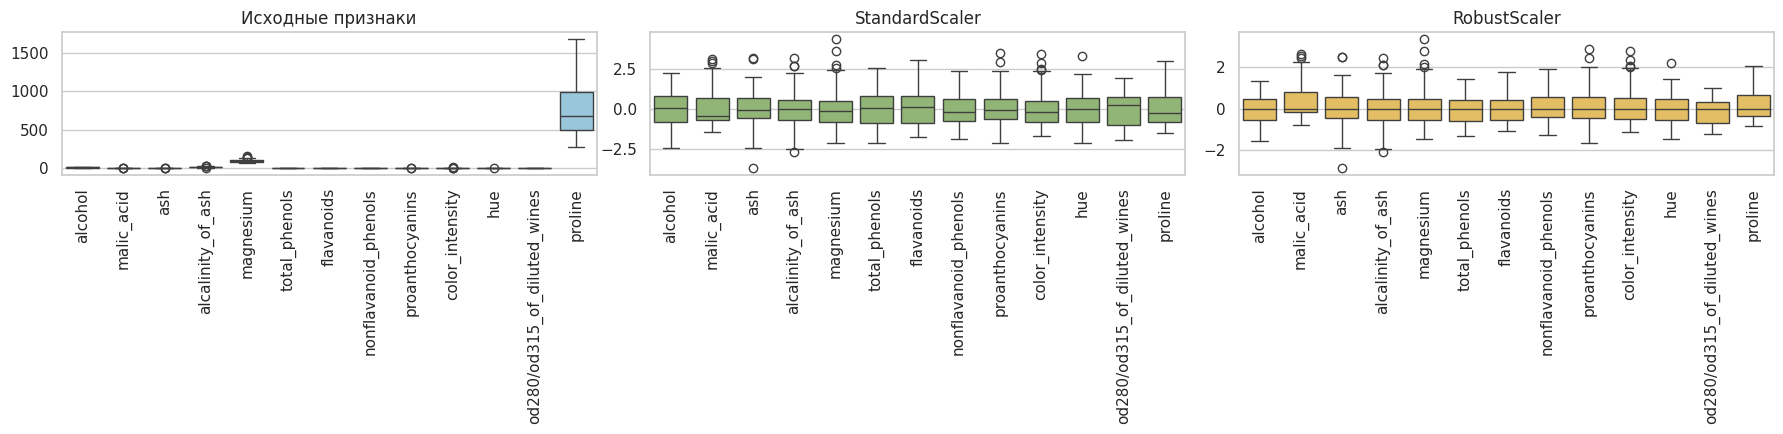

,Q05,Медиана,Q95,Среднее,Std расстояний
Представление,,,,,
Без масштабирования,30.864,282.172,880.096,352.637,272.819
StandardScaler,2.501,5.004,7.187,4.906,1.441
RobustScaler,1.781,3.512,5.088,3.458,1.010


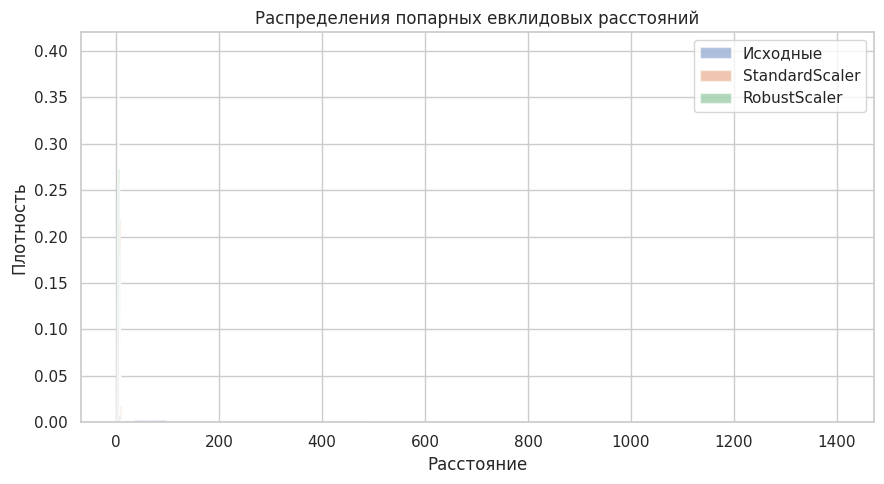

Признаки с наибольшим стандартным отклонением в исходных единицах:


,std,доля суммы дисперсий
proline,314.907,0.998
magnesium,14.282,0.002
alcalinity_of_ash,3.340,0.000
color_intensity,2.318,0.000
malic_acid,1.117,0.000
flavanoids,0.999,0.000


Выбор для основной модели: StandardScaler — у признаков становится сопоставимый масштаб и евклидовы расстояния не задаются одними только крупными единицами измерения. RobustScaler оставлен как проверка чувствительности к выбросам, поскольку центрирует по медиане и масштабирует по IQR.


In [4]:
# 2. Масштабирование и влияние единиц измерения
from sklearn.preprocessing import StandardScaler, RobustScaler

scaler_std = StandardScaler()
scaler_robust = RobustScaler()
Xs = scaler_std.fit_transform(X)
Xr = scaler_robust.fit_transform(X)

# Распределения величин признаков до и после масштабирования
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.boxplot(data=X, ax=axes[0], color='#8ecae6')
axes[0].set_title('Исходные признаки')
axes[0].tick_params(axis='x', rotation=90)
sns.boxplot(data=pd.DataFrame(Xs, columns=X.columns), ax=axes[1], color='#90be6d')
axes[1].set_title('StandardScaler')
axes[1].tick_params(axis='x', rotation=90)
sns.boxplot(data=pd.DataFrame(Xr, columns=X.columns), ax=axes[2], color='#f9c74f')
axes[2].set_title('RobustScaler')
axes[2].tick_params(axis='x', rotation=90)
plt.tight_layout()
plt.show()

# Pairwise distance distributions; exclude the diagonal zeros for meaningful quantiles
D_raw = pairwise_distances(X)
D_std = pairwise_distances(Xs)
D_robust = pairwise_distances(Xr)
tri = np.triu_indices(len(X), k=1)
distance_rows = []
for name, D in [('Без масштабирования', D_raw), ('StandardScaler', D_std), ('RobustScaler', D_robust)]:
    vals = D[tri]
    distance_rows.append({
        'Представление': name,
        'Q05': np.quantile(vals, .05), 'Медиана': np.median(vals),
        'Q95': np.quantile(vals, .95), 'Среднее': vals.mean(),
        'Std расстояний': vals.std()
    })
distance_summary = pd.DataFrame(distance_rows).set_index('Представление')
display(distance_summary.round(3))

fig, ax = plt.subplots(figsize=(9, 5))
for name, D in [('Исходные', D_raw), ('StandardScaler', D_std), ('RobustScaler', D_robust)]:
    ax.hist(D[tri], bins=45, alpha=.45, density=True, label=name)
ax.set(title='Распределения попарных евклидовых расстояний', xlabel='Расстояние', ylabel='Плотность')
ax.legend()
plt.tight_layout()
plt.show()

raw_scale = X.std().sort_values(ascending=False)
raw_variance_share = X.var() / X.var().sum()
print('Признаки с наибольшим стандартным отклонением в исходных единицах:')
display(pd.DataFrame({'std': raw_scale.head(6), 'доля суммы дисперсий': raw_variance_share.loc[raw_scale.head(6).index]}).round(3))
print('Выбор для основной модели: StandardScaler — у признаков становится сопоставимый масштаб и евклидовы расстояния не задаются одними только крупными единицами измерения. RobustScaler оставлен как проверка чувствительности к выбросам, поскольку центрирует по медиане и масштабирует по IQR.')

**Вывод.** Евклидово расстояние до масштабирования отражает не только профиль образца, но и единицы измерения признаков. Поэтому признаки с большими абсолютными значениями и разбросом могут доминировать в расстояниях, даже если их предметная важность не выше. `StandardScaler` делает сравнимыми масштабы дисперсий и выбран для основной модели расстояний; `RobustScaler` полезен как анализ чувствительности, поскольку меньше зависит от крайних значений. Масштабирование — часть определения геометрии кластеров, а не нейтральный технический шаг. Ни один scaler сам по себе не доказывает, что получившаяся геометрия соответствует прикладной цели.

## 3. K-means и диапазон K

**Цель:** Исследовать зависимость качества от числа кластеров.  
**Задание:** Для K=2…10 вычислить inertia, silhouette, Calinski–Harabasz и Davies–Bouldin. Построить графики. Не выбирать K только по одной метрике.  
**Ожидаемый результат:** Таблица метрик, 2–4 кандидата K и объяснение компромисса.

,inertia,silhouette,Calinski–Harabasz,Davies–Bouldin
K,,,,
2,1658.7589,0.2593,69.5233,1.5260
3,1277.9285,0.2849,70.9400,1.3892
4,1175.3519,0.2586,56.1888,1.8170
5,1107.0073,0.2315,47.1564,1.6811
6,1046.0023,0.2372,41.7008,1.5544
7,981.5952,0.2036,38.6855,1.6606
8,935.2012,0.1570,35.8053,1.7409
9,889.8929,0.1499,33.8066,1.7083
10,845.8952,0.1436,32.3972,1.7070


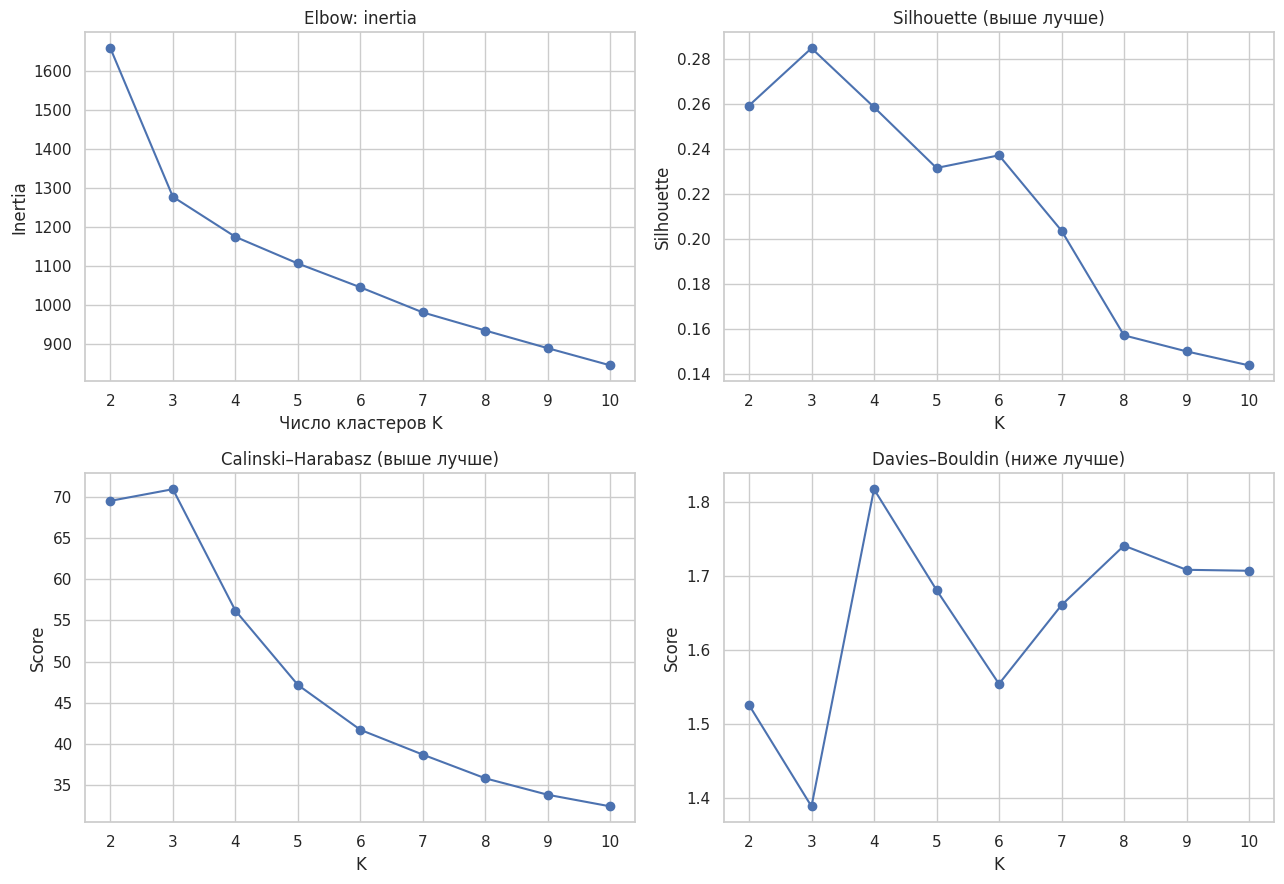

Максимум silhouette: K=3; максимум Calinski–Harabasz: K=3; минимум Davies–Bouldin: K=3.
Для последующего профилирования заранее фиксируем K=3 как интерпретируемого кандидата и сопоставляем его с K=2 и K=4 в анализе устойчивости; это решение не использует target.


In [5]:
# 3. K-means: подбор K по нескольким внутренним метрикам
rows = []
labels_by_k = {}
models_by_k = {}
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=30, random_state=RANDOM_STATE)
    lab = km.fit_predict(Xs)
    models_by_k[k] = km
    labels_by_k[k] = lab
    rows.append({
        'K': k,
        'inertia': km.inertia_,
        'silhouette': silhouette_score(Xs, lab),
        'Calinski–Harabasz': calinski_harabasz_score(Xs, lab),
        'Davies–Bouldin': davies_bouldin_score(Xs, lab),
    })
kmeans_metrics = pd.DataFrame(rows).set_index('K')
display(kmeans_metrics.round(4))

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes[0, 0].plot(kmeans_metrics.index, kmeans_metrics['inertia'], marker='o')
axes[0, 0].set(title='Elbow: inertia', xlabel='Число кластеров K', ylabel='Inertia')
axes[0, 1].plot(kmeans_metrics.index, kmeans_metrics['silhouette'], marker='o')
axes[0, 1].set(title='Silhouette (выше лучше)', xlabel='K', ylabel='Silhouette')
axes[1, 0].plot(kmeans_metrics.index, kmeans_metrics['Calinski–Harabasz'], marker='o')
axes[1, 0].set(title='Calinski–Harabasz (выше лучше)', xlabel='K', ylabel='Score')
axes[1, 1].plot(kmeans_metrics.index, kmeans_metrics['Davies–Bouldin'], marker='o')
axes[1, 1].set(title='Davies–Bouldin (ниже лучше)', xlabel='K', ylabel='Score')
for ax in axes.flat:
    ax.set_xticks(range(2, 11))
plt.tight_layout()
plt.show()

best_sil_k = int(kmeans_metrics['silhouette'].idxmax())
best_ch_k = int(kmeans_metrics['Calinski–Harabasz'].idxmax())
best_db_k = int(kmeans_metrics['Davies–Bouldin'].idxmin())
print(f'Максимум silhouette: K={best_sil_k}; максимум Calinski–Harabasz: K={best_ch_k}; минимум Davies–Bouldin: K={best_db_k}.')
print('Для последующего профилирования заранее фиксируем K=3 как интерпретируемого кандидата и сопоставляем его с K=2 и K=4 в анализе устойчивости; это решение не использует target.')
K_FINAL = 3

**Вывод.** Inertia закономерно уменьшается с ростом K, поэтому сама по себе не задаёт единственное оптимальное число кластеров. Silhouette, Calinski–Harabasz и Davies–Bouldin оценивают разные аспекты компактности и разделимости, и их предпочтения могут не совпадать; таблица и графики позволяют увидеть этот компромисс. Для дальнейшего описания фиксируется кандидат **K=3**: это удобная рабочая сегментация, которую дополнительно проверяем на устойчивость и сравниваем с альтернативами. Такой выбор не означает, что в данных доказано существование ровно трёх естественных групп. Изменение preprocessing или алгоритма может изменить как качество внутренних метрик, так и сами назначения.

## 4. Устойчивость K-means

**Цель:** Отделить удачный запуск от воспроизводимой структуры.  
**Задание:** Для выбранных K выполнить 30 запусков с разными random_state. Сравнить inertia, silhouette и попарный ARI между разбиениями. Затем выполнить bootstrap-оценку устойчивости.  
**Ожидаемый результат:** Распределения метрик и вывод о наиболее устойчивом K.

,inertia_median,inertia_IQR,silhouette_mean,silhouette_std
K,,,,
2,1659.0080,0.9432,0.2609,0.0203
3,1278.7608,2.0377,0.2840,0.0018
4,1188.1076,15.7914,0.2378,0.0237


median   mean    min    max
K оценка                                           
2 Bootstrap              0.652  0.667  0.154  1.000
  Разные инициализации   0.671  0.679 -0.005  1.000
3 Bootstrap              0.913  0.903  0.762  1.000
  Разные инициализации   0.964  0.949  0.865  1.000
4 Bootstrap              0.745  0.748  0.513  0.935
  Разные инициализации   0.714  0.720  0.497  1.000

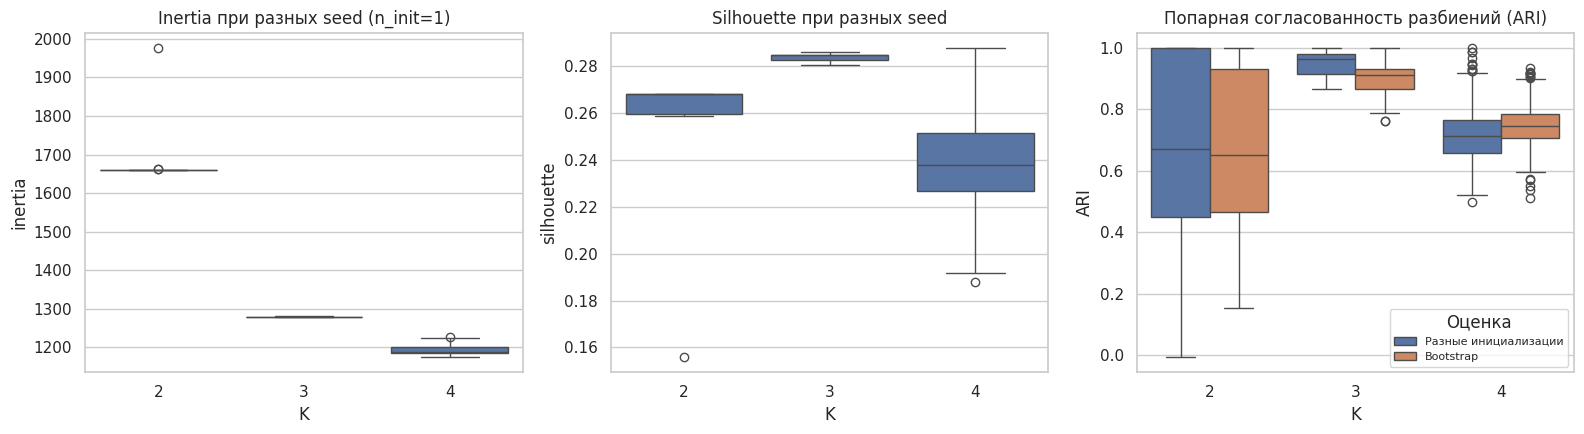

Медианный bootstrap ARI по K:


,median bootstrap ARI
K,
2,0.652
3,0.913
4,0.745


In [6]:
# 4. Устойчивость: разные инициализации и bootstrap
from sklearn.metrics import adjusted_rand_score

K_CANDIDATES = [2, 3, 4]
seed_metric_rows = []
seed_labelings = {k: [] for k in K_CANDIDATES}
for k in K_CANDIDATES:
    for seed in range(30):
        km = KMeans(n_clusters=k, n_init=1, random_state=seed)
        lab = km.fit_predict(Xs)
        seed_labelings[k].append(lab)
        seed_metric_rows.append({
            'K': k, 'seed': seed, 'inertia': km.inertia_,
            'silhouette': silhouette_score(Xs, lab)
        })
seed_metrics = pd.DataFrame(seed_metric_rows)

ari_seed_rows = []
for k in K_CANDIDATES:
    labs = seed_labelings[k]
    pairwise_ari = [adjusted_rand_score(labs[i], labs[j])
                    for i in range(len(labs)) for j in range(i)]
    ari_seed_rows.extend([{'K': k, 'ARI': value, 'оценка': 'Разные инициализации'} for value in pairwise_ari])

# Bootstrap: fit on samples drawn with replacement, then predict the same full data set
# for comparable assignments across replicates.
bootstrap_labelings = {k: [] for k in K_CANDIDATES}
rng = np.random.default_rng(RANDOM_STATE)
for k in K_CANDIDATES:
    for b in range(30):
        sample_idx = rng.integers(0, len(Xs), size=len(Xs))
        km = KMeans(n_clusters=k, n_init=10, random_state=1000 + b)
        km.fit(Xs[sample_idx])
        bootstrap_labelings[k].append(km.predict(Xs))
    labs = bootstrap_labelings[k]
    pairwise_ari = [adjusted_rand_score(labs[i], labs[j])
                    for i in range(len(labs)) for j in range(i)]
    ari_seed_rows.extend([{'K': k, 'ARI': value, 'оценка': 'Bootstrap'} for value in pairwise_ari])

stability_summary = seed_metrics.groupby('K').agg(
    inertia_median=('inertia', 'median'), inertia_IQR=('inertia', lambda x: x.quantile(.75)-x.quantile(.25)),
    silhouette_mean=('silhouette', 'mean'), silhouette_std=('silhouette', 'std')
)
ari_df = pd.DataFrame(ari_seed_rows)
ari_summary = ari_df.groupby(['K', 'оценка'])['ARI'].agg(['median', 'mean', 'min', 'max']).round(3)
display(stability_summary.round(4))
display(ari_summary)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(data=seed_metrics, x='K', y='inertia', ax=axes[0])
axes[0].set_title('Inertia при разных seed (n_init=1)')
sns.boxplot(data=seed_metrics, x='K', y='silhouette', ax=axes[1])
axes[1].set_title('Silhouette при разных seed')
sns.boxplot(data=ari_df, x='K', y='ARI', hue='оценка', ax=axes[2])
axes[2].set_title('Попарная согласованность разбиений (ARI)')
axes[2].legend(title='Оценка', fontsize=8)
plt.tight_layout()
plt.show()

bootstrap_median = ari_df[ari_df['оценка'] == 'Bootstrap'].groupby('K')['ARI'].median()
print('Медианный bootstrap ARI по K:')
display(bootstrap_median.rename('median bootstrap ARI').to_frame().round(3))

**Вывод.** Сравнение 30 запусков с `n_init=1` показывает, насколько результат зависит от начальных центроидов; разброс inertia и silhouette нельзя заменить одним «удачным» запуском. Попарный ARI сравнивает сами разбиения без зависимости от произвольной нумерации кластеров. Bootstrap-проверка дополнительно показывает, насколько назначения сохраняются, если обучать модель на повторных выборках исходного набора и прогнозировать все наблюдения. Для выбора K следует учитывать одновременно качество внутренних метрик и устойчивость seed/bootstrap, а не только их максимум. Устойчивость — необходимое, но не достаточное условие практической полезности сегментации.

## 5. Профили кластеров

**Цель:** Перевести геометрическое разбиение в предметное описание.  
**Задание:** Для выбранной модели вычислить размеры, медианы, IQR и standardized lift признаков. Найти типичный объект, ближайший к центроиду, и три пограничных объекта.  
**Ожидаемый результат:** Профиль каждого кластера и осторожное описательное название.

Размеры кластеров:


,n
cluster,
0,65
1,51
2,62


Медианы признаков в исходных единицах:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
cluster,,,,,,,,,,,,,
0,12.250,1.610,2.240,20.0,88.0,2.200,2.030,0.35,1.560,2.9,1.04,2.84,495.0
1,13.110,3.270,2.380,21.0,97.0,1.650,0.700,0.47,1.100,7.3,0.67,1.68,620.0
2,13.735,1.765,2.445,17.0,105.5,2.825,2.975,0.29,1.895,5.4,1.07,3.17,1072.5


IQR признаков по кластерам:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
cluster,,,,,,,,,,,,,
0,0.550,0.92,0.420,3.600,12.00,0.66,0.810,0.160,0.520,0.800,0.290,0.700,219.00
1,0.715,1.32,0.300,3.000,17.00,0.37,0.445,0.130,0.515,3.765,0.175,0.295,170.00
2,0.797,0.28,0.325,2.875,17.25,0.40,0.567,0.068,0.435,1.700,0.142,0.578,303.75


Standardized lift медиан (относительно общего среднего / SD):


cluster,0,1,2
alcohol,-0.92,0.13,0.90
malic_acid,-0.65,0.84,-0.51
ash,-0.46,0.05,0.29
alcalinity_of_ash,0.15,0.45,-0.75
magnesium,-0.82,-0.19,0.40
total_phenols,-0.15,-1.03,0.85
flavanoids,0.00,-1.33,0.95
nonflavanoid_phenols,-0.10,0.87,-0.58
proanthocyanins,-0.05,-0.86,0.53
color_intensity,-0.93,0.97,0.15


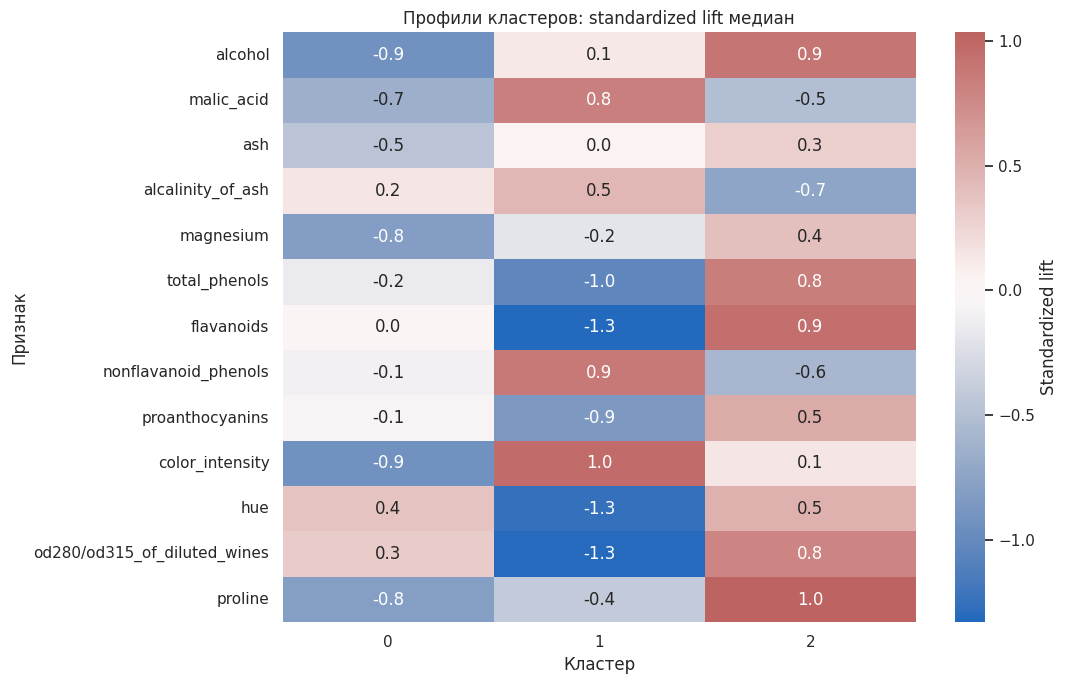

,Размер,Признаки с высоким lift,Признаки с низким lift
Кластер,,,
0,65,"hue, od280/od315_of_diluted_wines, alcalinity_...","color_intensity, alcohol, magnesium"
1,51,"color_intensity, nonflavanoid_phenols, malic_acid","flavanoids, od280/od315_of_diluted_wines, hue"
2,62,"proline, flavanoids, alcohol","alcalinity_of_ash, nonflavanoid_phenols, malic..."


Типичные объекты — ближайшие к центроиду внутри кластера:


,Индекс объекта,Расстояние до центроида
Кластер,,
0,106,1.5477
1,148,1.0794
2,48,1.3427


Три наиболее пограничных объекта (минимальный разрыв между двумя ближайшими центроидами):


,Кластер,Ближайший центроид,Второй центроид,Запас до второго центроида
Индекс объекта,,,,
61,1,3.3966,3.5210,0.1244
121,2,6.1616,6.3267,0.1650
71,0,3.8318,4.0122,0.1804


In [7]:
# 5. Профили кластеров на исходной шкале и в standardized lift
kmeans_final = KMeans(n_clusters=K_FINAL, n_init=50, random_state=RANDOM_STATE).fit(Xs)
labels = kmeans_final.labels_

cluster_sizes = pd.Series(labels, name='cluster').value_counts().sort_index().rename('n')
medians = X.assign(cluster=labels).groupby('cluster').median()
q25 = X.assign(cluster=labels).groupby('cluster').quantile(.25)
q75 = X.assign(cluster=labels).groupby('cluster').quantile(.75)
iqr = q75 - q25
# Standardized lift: cluster median relative to whole-sample mean, in whole-sample SD units.
profile_z = (medians - X.mean()) / X.std(ddof=1)
print('Размеры кластеров:')
display(cluster_sizes.to_frame())
print('Медианы признаков в исходных единицах:')
display(medians.round(3))
print('IQR признаков по кластерам:')
display(iqr.round(3))
print('Standardized lift медиан (относительно общего среднего / SD):')
display(profile_z.T.round(2))

plt.figure(figsize=(11, 7))
sns.heatmap(profile_z.T, center=0, cmap='vlag', annot=True, fmt='.1f',
            cbar_kws={'label': 'Standardized lift'})
plt.title('Профили кластеров: standardized lift медиан')
plt.xlabel('Кластер')
plt.ylabel('Признак')
plt.tight_layout()
plt.show()

# Concise descriptive—not semantic—profile names from strongest positive/negative lifts.
profile_names = {}
profile_rows = []
for cluster in sorted(np.unique(labels)):
    vals = profile_z.loc[cluster]
    high = vals.sort_values(ascending=False).head(3).index.tolist()
    low = vals.sort_values().head(3).index.tolist()
    profile_names[int(cluster)] = f'Профиль {int(cluster)}'
    profile_rows.append({
        'Кластер': int(cluster), 'Размер': int(cluster_sizes.loc[cluster]),
        'Признаки с высоким lift': ', '.join(high),
        'Признаки с низким lift': ', '.join(low)
    })
display(pd.DataFrame(profile_rows).set_index('Кластер'))

# Typical observation: closest member to that cluster's fitted centroid.
dist_to_centers = kmeans_final.transform(Xs)
typical_rows = []
for cluster in range(K_FINAL):
    members = np.flatnonzero(labels == cluster)
    local_dist = dist_to_centers[members, cluster]
    idx = int(members[np.argmin(local_dist)])
    typical_rows.append({'Кластер': cluster, 'Индекс объекта': X.index[idx],
                         'Расстояние до центроида': dist_to_centers[idx, cluster]})
print('Типичные объекты — ближайшие к центроиду внутри кластера:')
display(pd.DataFrame(typical_rows).set_index('Кластер').round(4))

# Borderline observations: smallest margin between nearest and second-nearest centroids.
ordered_dist = np.sort(dist_to_centers, axis=1)
margin = ordered_dist[:, 1] - ordered_dist[:, 0]
border_idx = np.argsort(margin)[:3]
borderline = pd.DataFrame({
    'Индекс объекта': X.index[border_idx], 'Кластер': labels[border_idx],
    'Ближайший центроид': ordered_dist[border_idx, 0],
    'Второй центроид': ordered_dist[border_idx, 1],
    'Запас до второго центроида': margin[border_idx]
}).set_index('Индекс объекта')
print('Три наиболее пограничных объекта (минимальный разрыв между двумя ближайшими центроидами):')
display(borderline.round(4))

**Вывод.** Медианы и IQR описывают типичные значения и внутрикластерный разброс в исходных единицах, а standardized lift делает различия признаков сопоставимыми. Тепловая карта помогает найти признаки, относительно повышенные или пониженные в каждом кластере, но такие профили остаются описательными, а не причинными объяснениями. Типичный объект определён как ближайший к своему центроиду; пограничные объекты имеют малую разницу расстояний до двух ближайших центроидов и поэтому потенциально чувствительны к изменению модели. Названия профилей следует формулировать через измеренные признаки, не приписывая им качество, происхождение или другие свойства, которых эти данные не подтверждают.

## 6. Иерархическая модель

**Цель:** Исследовать альтернативную геометрическую гипотезу.  
**Задание:** Сравнить Ward, complete, average и single linkage. Построить дендрограмму. Выбрать уровень разреза и сравнить разбиение с K-means через ARI.  
**Ожидаемый результат:** Дендрограмма, таблица сравнений и объяснение эффекта linkage.

,число кластеров,silhouette,Calinski–Harabasz,Davies–Bouldin,ARI vs K-means,размеры кластеров
linkage,,,,,,
ward,3,0.2774,67.6475,1.4186,0.8530,"[56, 58, 64]"
complete,3,0.2038,48.9898,1.8961,0.5959,"[51, 58, 69]"
average,3,0.1575,4.0314,1.0299,-0.0016,"[1, 3, 174]"
single,3,0.1827,4.0617,0.9105,-0.0028,"[1, 3, 174]"


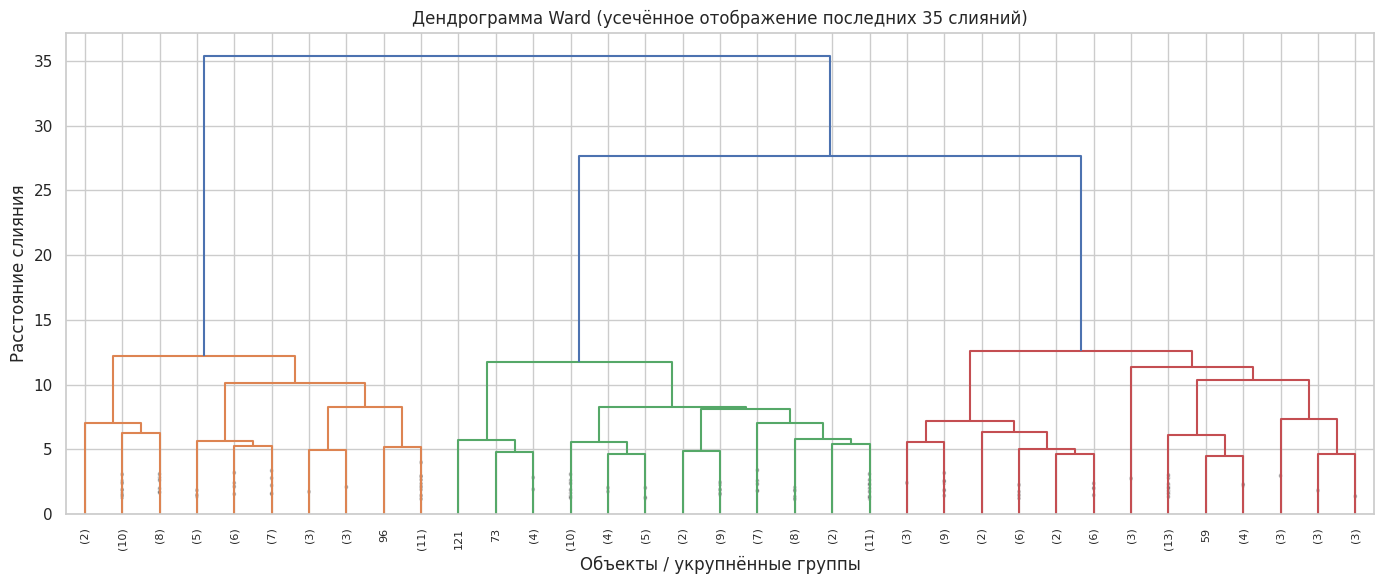

Наибольший silhouette среди заданных linkage: ward.
Ward оптимизирует прирост внутрикластерной суммы квадратов; complete предпочитает группы с ограниченным максимальным попарным расстоянием; average усредняет межкластерные расстояния; single может образовывать цепочки через близкие соседние точки.


In [8]:
# 6. Иерархическая кластеризация: разные linkage
from sklearn.cluster import AgglomerativeClustering
linkage_names = ['ward', 'complete', 'average', 'single']
hierarchical_labels = {}
hierarchical_rows = []
for method in linkage_names:
    lab = AgglomerativeClustering(n_clusters=K_FINAL, linkage=method).fit_predict(Xs)
    hierarchical_labels[method] = lab
    hierarchical_rows.append({
        'linkage': method,
        'число кластеров': len(np.unique(lab)),
        'silhouette': silhouette_score(Xs, lab),
        'Calinski–Harabasz': calinski_harabasz_score(Xs, lab),
        'Davies–Bouldin': davies_bouldin_score(Xs, lab),
        'ARI vs K-means': adjusted_rand_score(labels, lab),
        'размеры кластеров': sorted(pd.Series(lab).value_counts().tolist())
    })
hierarchical_metrics = pd.DataFrame(hierarchical_rows).set_index('linkage')
display(hierarchical_metrics.round(4))

# Dendrogram for Ward linkage; truncation improves readability without changing fitted labels above.
Z_ward = scipy_linkage(Xs, method='ward', metric='euclidean')
plt.figure(figsize=(14, 6))
dendrogram(Z_ward, truncate_mode='lastp', p=35, leaf_rotation=90,
           leaf_font_size=8, show_contracted=True)
plt.title('Дендрограмма Ward (усечённое отображение последних 35 слияний)')
plt.xlabel('Объекты / укрупнённые группы')
plt.ylabel('Расстояние слияния')
plt.tight_layout()
plt.show()

best_hier_linkage = hierarchical_metrics['silhouette'].idxmax()
print(f'Наибольший silhouette среди заданных linkage: {best_hier_linkage}.')
print('Ward оптимизирует прирост внутрикластерной суммы квадратов; complete предпочитает группы с ограниченным максимальным попарным расстоянием; average усредняет межкластерные расстояния; single может образовывать цепочки через близкие соседние точки.')

**Вывод.** Иерархические алгоритмы построены на одном и том же стандартизованном представлении, а потому различия отражают прежде всего способ определения расстояния между группами. Ward обычно формирует компактные группы, complete сильнее учитывает удалённые пары, average использует среднее расстояние, а single подвержен эффекту «цепочки». Дендрограмма Ward показывает последовательность слияний; высота слияния сама по себе не является меткой истинной структуры и выбор уровня разреза остаётся решением аналитика. ARI относительно K-means оценивает совпадение разбиений независимо от номеров кластеров, но не утверждает, что одна модель правильна. Итоговое предпочтение должно учитывать внутренние метрики, профили и устойчивость.

## 7. DBSCAN/HDBSCAN

**Цель:** Изучить плотностную кластеризацию и понятие шума.  
**Задание:** Построить k-distance plot. Исследовать сетку eps и min_samples для DBSCAN. Зафиксировать число кластеров, долю шума и silhouette по не-шумовым точкам. Дополнительно применить HDBSCAN при доступной версии.  
**Ожидаемый результат:** Карта параметров, объяснение выбранного режима и природы шума.

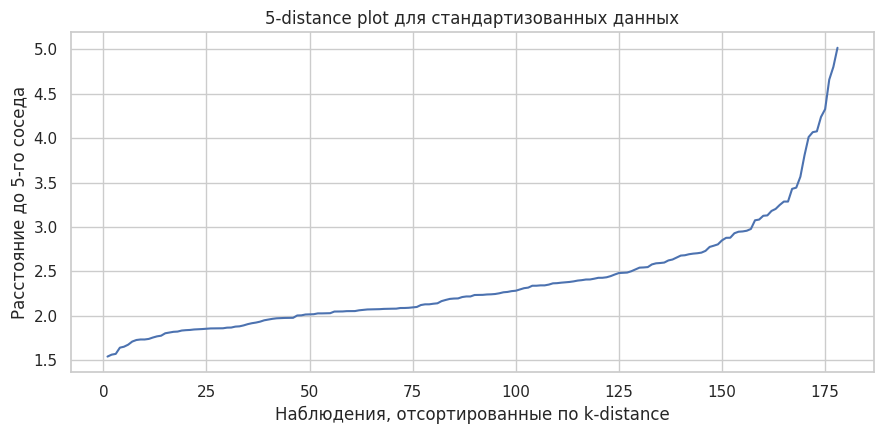

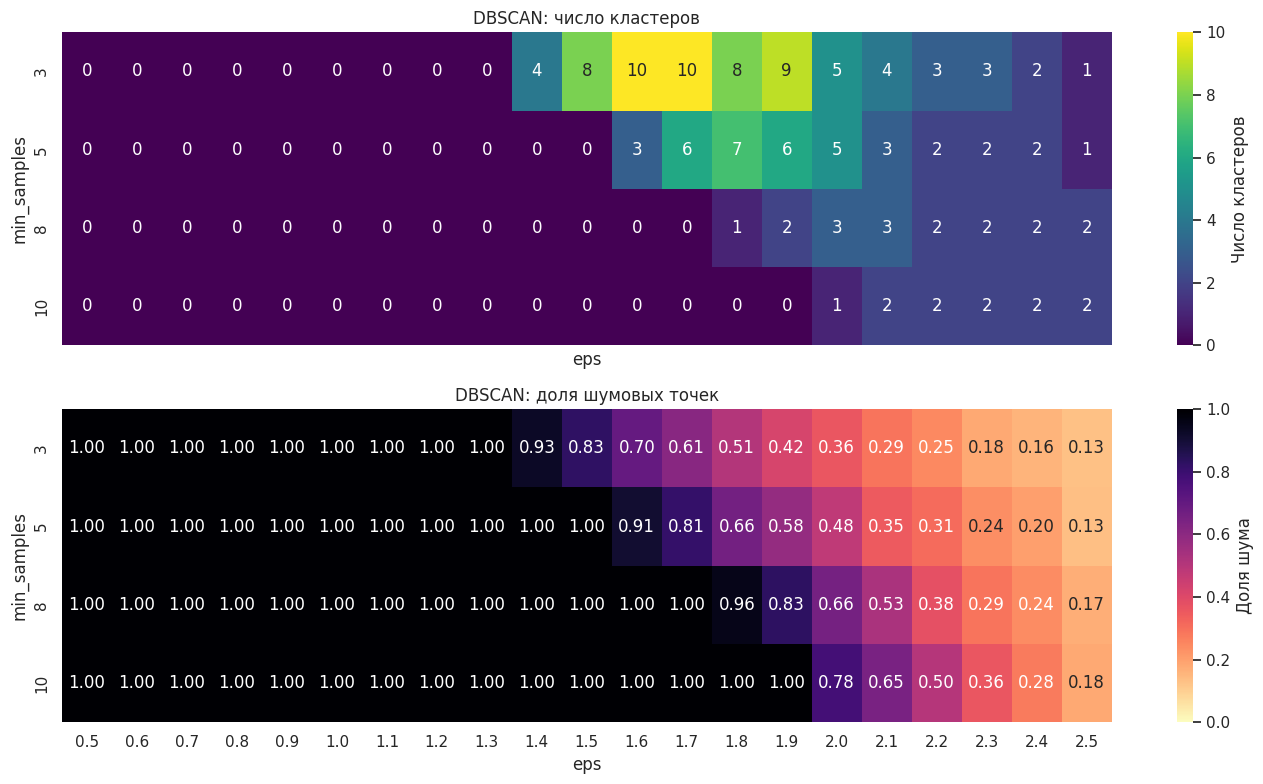

Выбранный DBSCAN режим: (2.2, 10) | правило: максимальный silhouette среди режимов с 2–8 кластерами и не более 50% шума


,eps,min_samples,clusters,noise_fraction,silhouette_non_noise
80,2.2,10.0,2.0,0.5,0.394


Лучшие строки сетки по silhouette (если он определён):


,eps,min_samples,clusters,noise_fraction,silhouette_non_noise
56,1.9,8,2,0.8315,0.5856
9,1.4,3,4,0.9270,0.5330
32,1.6,5,3,0.9101,0.5021
57,2.0,8,3,0.6573,0.4360
79,2.1,10,2,0.6461,0.4228
33,1.7,5,6,0.8146,0.3943
80,2.2,10,2,0.5000,0.3940
81,2.3,10,2,0.3596,0.3641
59,2.2,8,2,0.3764,0.3505
35,1.9,5,6,0.5787,0.3490


,Метод,min_cluster_size,min_samples,число кластеров,доля шума,silhouette без шума
0,HDBSCAN,5,5,2,0.3258,0.3524


In [9]:
# 7. DBSCAN и HDBSCAN: плотность и шум
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

# k-distance plot (k=5) помогает ориентироваться в масштабе eps, но elbow не всегда выражен.
k = 5
nn = NearestNeighbors(n_neighbors=k).fit(Xs)
distances, _ = nn.kneighbors(Xs)
k_dist = np.sort(distances[:, -1])
plt.figure(figsize=(9, 4.5))
plt.plot(np.arange(1, len(k_dist)+1), k_dist)
plt.title(f'{k}-distance plot для стандартизованных данных')
plt.xlabel('Наблюдения, отсортированные по k-distance')
plt.ylabel(f'Расстояние до {k}-го соседа')
plt.tight_layout()
plt.show()

# Parameter grid: record cluster count, noise share, and silhouette for non-noise points.
eps_values = np.round(np.arange(0.5, 2.51, 0.1), 2)
min_samples_values = [3, 5, 8, 10]
dbscan_rows = []
dbscan_models = {}
for ms in min_samples_values:
    for eps in eps_values:
        model = DBSCAN(eps=float(eps), min_samples=int(ms))
        lab = model.fit_predict(Xs)
        n_clusters = len(set(lab)) - (1 if -1 in lab else 0)
        noise_fraction = float(np.mean(lab == -1))
        mask = lab != -1
        sil = np.nan
        if n_clusters >= 2 and mask.sum() > n_clusters:
            sil = silhouette_score(Xs[mask], lab[mask])
        dbscan_models[(float(eps), int(ms))] = (model, lab)
        dbscan_rows.append({'eps': eps, 'min_samples': ms, 'clusters': n_clusters,
                            'noise_fraction': noise_fraction, 'silhouette_non_noise': sil})
dbscan_grid = pd.DataFrame(dbscan_rows)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
piv_clusters = dbscan_grid.pivot(index='min_samples', columns='eps', values='clusters')
piv_noise = dbscan_grid.pivot(index='min_samples', columns='eps', values='noise_fraction')
sns.heatmap(piv_clusters, cmap='viridis', annot=True, fmt='g', ax=axes[0], cbar_kws={'label':'Число кластеров'})
axes[0].set_title('DBSCAN: число кластеров')
sns.heatmap(piv_noise, cmap='magma_r', annot=True, fmt='.2f', ax=axes[1], cbar_kws={'label':'Доля шума'}, vmin=0, vmax=1)
axes[1].set_title('DBSCAN: доля шумовых точек')
axes[1].set_xlabel('eps')
plt.tight_layout()
plt.show()

valid_db = dbscan_grid[
    (dbscan_grid['clusters'] >= 2) &
    (dbscan_grid['clusters'] <= 8) &
    (dbscan_grid['noise_fraction'] <= 0.50) &
    dbscan_grid['silhouette_non_noise'].notna()
].copy()
if len(valid_db):
    best_db_row = valid_db.sort_values(['silhouette_non_noise', 'noise_fraction'], ascending=[False, True]).iloc[0]
    selection_rule = 'максимальный silhouette среди режимов с 2–8 кластерами и не более 50% шума'
else:
    valid_db = dbscan_grid[dbscan_grid['silhouette_non_noise'].notna()].copy()
    if len(valid_db):
        best_db_row = valid_db.sort_values(['silhouette_non_noise', 'noise_fraction'], ascending=[False, True]).iloc[0]
        selection_rule = 'лучший доступный silhouette; ни один режим не прошёл предпочтительный фильтр'
    else:
        best_db_row = dbscan_grid.sort_values(['noise_fraction', 'clusters'], ascending=[True, False]).iloc[0]
        selection_rule = 'наименьшая доля шума при максимальном числе кластеров среди проверенных режимов; silhouette не определён'
sel_key = (float(best_db_row['eps']), int(best_db_row['min_samples']))
dbscan_selected_model, dbscan_labels_selected = dbscan_models[sel_key]
print('Выбранный DBSCAN режим:', sel_key, '| правило:', selection_rule)
display(pd.DataFrame([best_db_row]).round(4))
print('Лучшие строки сетки по silhouette (если он определён):')
display(dbscan_grid.dropna(subset=['silhouette_non_noise']).sort_values('silhouette_non_noise', ascending=False).head(10).round(4))

# HDBSCAN is included in newer scikit-learn versions; gracefully skip if unavailable.
hdbscan_labels = None
try:
    from sklearn.cluster import HDBSCAN
    hdbscan_model = HDBSCAN(min_cluster_size=5, min_samples=5)
    hdbscan_labels = hdbscan_model.fit_predict(Xs)
    hdb_n_clusters = len(set(hdbscan_labels)) - (1 if -1 in hdbscan_labels else 0)
    hdb_noise = float(np.mean(hdbscan_labels == -1))
    hdb_mask = hdbscan_labels != -1
    hdb_sil = (silhouette_score(Xs[hdb_mask], hdbscan_labels[hdb_mask])
               if hdb_n_clusters >= 2 and hdb_mask.sum() > hdb_n_clusters else np.nan)
    display(pd.DataFrame([{'Метод':'HDBSCAN', 'min_cluster_size':5, 'min_samples':5,
                           'число кластеров':hdb_n_clusters, 'доля шума':hdb_noise,
                           'silhouette без шума':hdb_sil}]).round(4))
except (ImportError, TypeError, ValueError) as exc:
    print('HDBSCAN не удалось запустить в текущей среде:', repr(exc))

**Вывод.** DBSCAN зависит от пары `eps`/`min_samples`: слишком малый радиус может объявить почти все точки шумом, а слишком большой — слить данные в один кластер. k-distance plot даёт масштаб для поиска возможного излома, но не гарантирует единственной правильной настройки. В сетке параметры сопоставлены по числу кластеров, доле шума и silhouette только на не-шумовых точках; последняя метрика не оценивает корректность отнесения шума. Отрицательные метки означают лишь, что объект не оказался в плотной области при выбранных параметрах, а не что объект является бизнес-аномалией. HDBSCAN полезен как дополнительная проверка переменной плотности, но при малом наборе результат также зависит от параметров и требует осторожной интерпретации.

## 8. Gaussian Mixture

**Цель:** Получить мягкие назначения и исследовать неопределенность.  
**Задание:** Сравнить covariance_type и K по BIC/AIC. Для выбранной модели проанализировать max probability и entropy. Найти наиболее неоднозначные объекты.  
**Ожидаемый результат:** Графики BIC/AIC, таблица неоднозначных наблюдений.

,covariance_type,K,BIC,AIC,converged,iterations
7,diag,4,5476.48,5136.03,True,13
13,tied,5,5502.63,4993.54,True,5
14,tied,6,5516.29,4962.66,True,15
8,diag,5,5519.96,5093.60,True,32
12,tied,4,5529.87,5065.33,True,30
6,diag,3,5543.37,5288.82,True,9
9,diag,6,5560.88,5048.62,True,21
11,tied,3,5570.94,5150.94,True,5
15,full,2,5608.35,4943.36,True,21
4,spherical,6,5634.35,5351.17,True,19


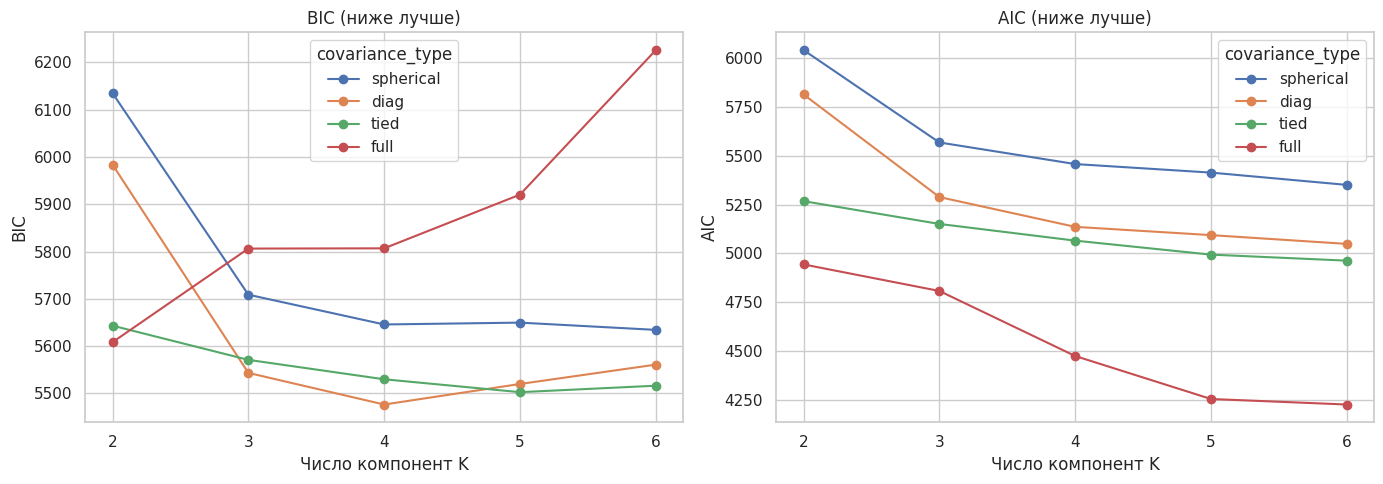

Лучшая по BIC модель: covariance_type=diag, K=4, BIC=5476.48, AIC=5136.03.
Сводка уверенности мягких назначений:


,max_probability,entropy
count,178.0000,178.0000
mean,0.9852,0.0422
std,0.0557,0.1180
min,0.5997,0.0000
25%,0.9976,0.0000
50%,1.0000,0.0002
75%,1.0000,0.0170
max,1.0000,0.7377


10 наиболее неоднозначных объектов (наибольшая энтропия):


,назначенный компонент,максимальная вероятность,энтропия
Индекс объекта,,,
81,3,0.5997,0.7377
84,2,0.6126,0.6676
94,2,0.6517,0.6464
122,3,0.7416,0.5714
65,3,0.8764,0.3780
93,2,0.8813,0.3644
118,2,0.8830,0.3612
126,3,0.8865,0.3538
96,3,0.9078,0.3178


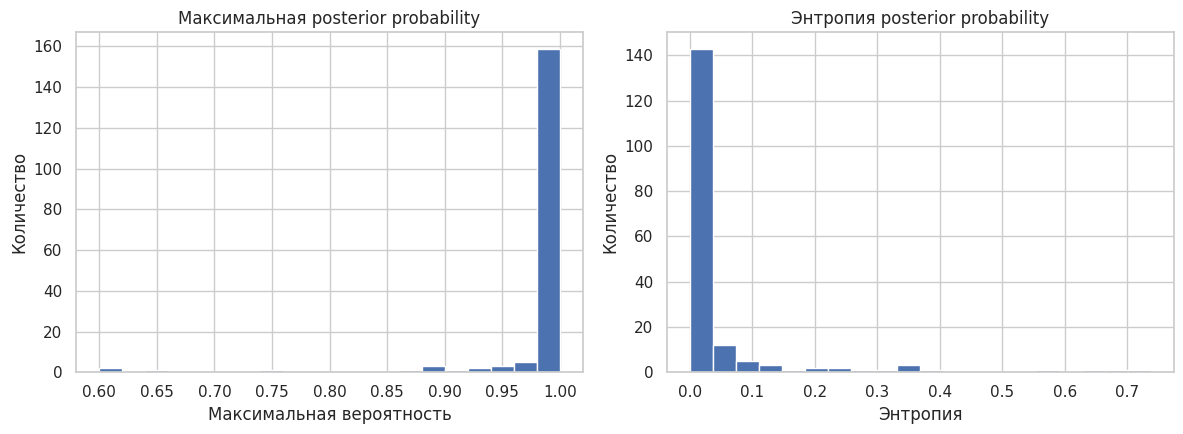

In [10]:
# 8. Gaussian Mixture: AIC/BIC и неопределённость мягких назначений
from sklearn.mixture import GaussianMixture

gmm_rows = []
gmm_models = {}
for cov in ['spherical', 'diag', 'tied', 'full']:
    for k_gmm in range(2, 7):
        gm = GaussianMixture(n_components=k_gmm, covariance_type=cov,
                             n_init=10, random_state=RANDOM_STATE, reg_covar=1e-6)
        gm.fit(Xs)
        gmm_models[(cov, k_gmm)] = gm
        gmm_rows.append({'covariance_type': cov, 'K': k_gmm,
                         'BIC': gm.bic(Xs), 'AIC': gm.aic(Xs),
                         'converged': gm.converged_, 'iterations': gm.n_iter_})
gmm_metrics = pd.DataFrame(gmm_rows)
display(gmm_metrics.sort_values('BIC').round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for cov in ['spherical', 'diag', 'tied', 'full']:
    sub = gmm_metrics[gmm_metrics['covariance_type'] == cov].sort_values('K')
    axes[0].plot(sub['K'], sub['BIC'], marker='o', label=cov)
    axes[1].plot(sub['K'], sub['AIC'], marker='o', label=cov)
axes[0].set(title='BIC (ниже лучше)', xlabel='Число компонент K', ylabel='BIC')
axes[1].set(title='AIC (ниже лучше)', xlabel='Число компонент K', ylabel='AIC')
for ax in axes:
    ax.set_xticks(range(2, 7))
    ax.legend(title='covariance_type')
plt.tight_layout()
plt.show()

best_gmm_row = gmm_metrics.sort_values('BIC').iloc[0]
best_gmm_key = (str(best_gmm_row['covariance_type']), int(best_gmm_row['K']))
gmm_best = gmm_models[best_gmm_key]
gmm_labels = gmm_best.predict(Xs)
gmm_probs = gmm_best.predict_proba(Xs)
max_prob = gmm_probs.max(axis=1)
entropy = -(gmm_probs * np.log(np.clip(gmm_probs, 1e-12, 1))).sum(axis=1)
print(f"Лучшая по BIC модель: covariance_type={best_gmm_key[0]}, K={best_gmm_key[1]}, BIC={best_gmm_row['BIC']:.2f}, AIC={best_gmm_row['AIC']:.2f}.")
print('Сводка уверенности мягких назначений:')
display(pd.DataFrame({'max_probability': max_prob, 'entropy': entropy}).describe().round(4))

ambiguous_idx = np.argsort(-entropy)[:10]
ambiguous = pd.DataFrame({
    'Индекс объекта': X.index[ambiguous_idx],
    'назначенный компонент': gmm_labels[ambiguous_idx],
    'максимальная вероятность': max_prob[ambiguous_idx],
    'энтропия': entropy[ambiguous_idx],
}).set_index('Индекс объекта')
print('10 наиболее неоднозначных объектов (наибольшая энтропия):')
display(ambiguous.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(max_prob, bins=20, edgecolor='white')
axes[0].set(title='Максимальная posterior probability', xlabel='Максимальная вероятность', ylabel='Количество')
axes[1].hist(entropy, bins=20, edgecolor='white')
axes[1].set(title='Энтропия posterior probability', xlabel='Энтропия', ylabel='Количество')
plt.tight_layout()
plt.show()

**Вывод.** AIC и BIC сравнивают качество подгонки с учётом сложности модели; меньшие значения предпочтительнее внутри сравниваемой постановки, однако они не гарантируют бизнес-полезности компонентов. В Gaussian Mixture наблюдение получает вероятности принадлежности ко всем компонентам, а не только жёсткую метку. Низкая максимальная вероятность и высокая энтропия указывают на неоднозначное назначение, поэтому такие наблюдения разумно проверять отдельно. Выбранная по BIC конфигурация используется далее для диагностики, но сравнение результатов следует проводить с учётом разных предположений о форме кластеров и чувствительности GMM к распределению данных.

## 9. PCA

**Цель:** Освоить линейное снижение размерности и интерпретацию компонент.  
**Задание:** Обучить PCA на scaled data. Построить scree и cumulative variance. Найти минимальное число компонент для 80%, 90% и 95%. Проанализировать loadings первых трех компонент.  
**Ожидаемый результат:** Графики, таблица loadings и содержательное описание осей.

,Компонента,Объяснённая дисперсия,Накопленная дисперсия
0,PC1,0.3620,0.3620
1,PC2,0.1921,0.5541
2,PC3,0.1112,0.6653
3,PC4,0.0707,0.7360
4,PC5,0.0656,0.8016
5,PC6,0.0494,0.8510
6,PC7,0.0424,0.8934
7,PC8,0.0268,0.9202
8,PC9,0.0222,0.9424
9,PC10,0.0193,0.9617


,Минимальное число компонент,Фактическая накопленная дисперсия
Порог накопленной дисперсии,,
0.80,5,0.8016
0.90,8,0.9202
0.95,10,0.9617


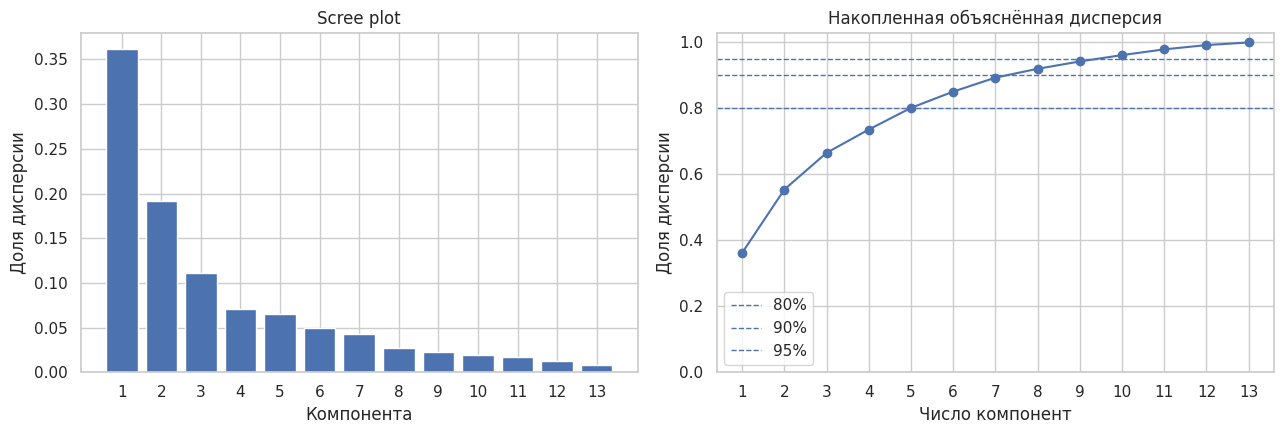

Нагрузки первых трёх компонент (знак задаёт направление, абсолютная величина — вклад в ось):


,PC1,PC2,PC3
alcohol,0.144,0.484,-0.207
malic_acid,-0.245,0.225,0.089
ash,-0.002,0.316,0.626
alcalinity_of_ash,-0.239,-0.011,0.612
magnesium,0.142,0.300,0.131
total_phenols,0.395,0.065,0.146
flavanoids,0.423,-0.003,0.151
nonflavanoid_phenols,-0.299,0.029,0.170
proanthocyanins,0.313,0.039,0.149
color_intensity,-0.089,0.530,-0.137


PC1: наибольшие по абсолютной величине нагрузки — flavanoids, total_phenols, od280/od315_of_diluted_wines, proanthocyanins, nonflavanoid_phenols
PC2: наибольшие по абсолютной величине нагрузки — color_intensity, alcohol, proline, ash, magnesium
PC3: наибольшие по абсолютной величине нагрузки — ash, alcalinity_of_ash, alcohol, nonflavanoid_phenols, od280/od315_of_diluted_wines


In [11]:
# 9. PCA: объяснённая дисперсия и интерпретация нагрузок
pca = PCA().fit(Xs)
explained = pca.explained_variance_ratio_
cum = np.cumsum(explained)
pca_variance = pd.DataFrame({
    'Компонента': [f'PC{i+1}' for i in range(len(explained))],
    'Объяснённая дисперсия': explained,
    'Накопленная дисперсия': cum
})
display(pca_variance.round(4))

threshold_rows = []
for threshold in [.80, .90, .95]:
    n_comp = int(np.searchsorted(cum, threshold) + 1)
    threshold_rows.append({'Порог накопленной дисперсии': threshold,
                           'Минимальное число компонент': n_comp,
                           'Фактическая накопленная дисперсия': cum[n_comp-1]})
display(pd.DataFrame(threshold_rows).set_index('Порог накопленной дисперсии').round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
x = np.arange(1, len(explained)+1)
axes[0].bar(x, explained)
axes[0].set(title='Scree plot', xlabel='Компонента', ylabel='Доля дисперсии')
axes[0].set_xticks(x)
axes[1].plot(x, cum, marker='o')
axes[1].axhline(.80, linestyle='--', linewidth=1, label='80%')
axes[1].axhline(.90, linestyle='--', linewidth=1, label='90%')
axes[1].axhline(.95, linestyle='--', linewidth=1, label='95%')
axes[1].set(title='Накопленная объяснённая дисперсия', xlabel='Число компонент', ylabel='Доля дисперсии', ylim=(0, 1.03))
axes[1].set_xticks(x)
axes[1].legend()
plt.tight_layout()
plt.show()

loadings = pd.DataFrame(pca.components_.T, index=X.columns,
                        columns=[f'PC{i+1}' for i in range(X.shape[1])])
print('Нагрузки первых трёх компонент (знак задаёт направление, абсолютная величина — вклад в ось):')
display(loadings.iloc[:, :3].round(3))
for pc in ['PC1', 'PC2', 'PC3']:
    top = loadings[pc].abs().sort_values(ascending=False).head(5).index.tolist()
    print(f'{pc}: наибольшие по абсолютной величине нагрузки — {", ".join(top)}')

**Вывод.** PCA строит ортогональные линейные направления максимальной дисперсии в стандартизованном пространстве. Scree plot показывает вклад каждой компоненты, а накопленная кривая — сколько общей дисперсии сохраняется при сокращении размерности; минимальные числа компонент для 80%, 90% и 95% вычислены явно. Нагрузка характеризует вклад исходного признака в компоненту, причём знак оси условен: её можно развернуть без изменения решения PCA. Первые компоненты интерпретируются через сочетания признаков с наибольшими абсолютными нагрузками, а не как отдельные исходные измерения. Объяснённая дисперсия не равна полезности для конкретной downstream-задачи и сама по себе не определяет хорошую кластеризацию.

## 10. Внешняя диагностика

**Цель:** Понять разницу между структурой и известными классами.  
**Задание:** Только теперь открыть y_hidden. Вычислить ARI и NMI для выбранных моделей. Построить contingency table. Объяснить, почему ARI не использовался для unsupervised-настройки.  
**Ожидаемый результат:** Внешние метрики и интерпретация расхождений.

,ARI,NMI,Число назначенных меток (вкл. noise),Доля noise
Модель,,,,
K-means (K=3),0.8975,0.8759,3,0.0000
Hierarchical Ward (K=3),0.7899,0.7865,3,0.0000
"Gaussian Mixture ('diag', 4)",0.6832,0.7350,4,0.0000
HDBSCAN,0.3422,0.4295,3,0.3258
DBSCAN selected,0.2598,0.3556,3,0.5000


Contingency table для выбранного K-means (абсолютные количества):


кластер,0,1,2
известный класс,,,
0,0,0,59
1,65,3,3
2,0,48,0


Та же таблица, нормированная по строкам известного класса:


кластер,0,1,2
известный класс,,,
0,0.000,0.000,1.000
1,0.915,0.042,0.042
2,0.000,1.000,0.000


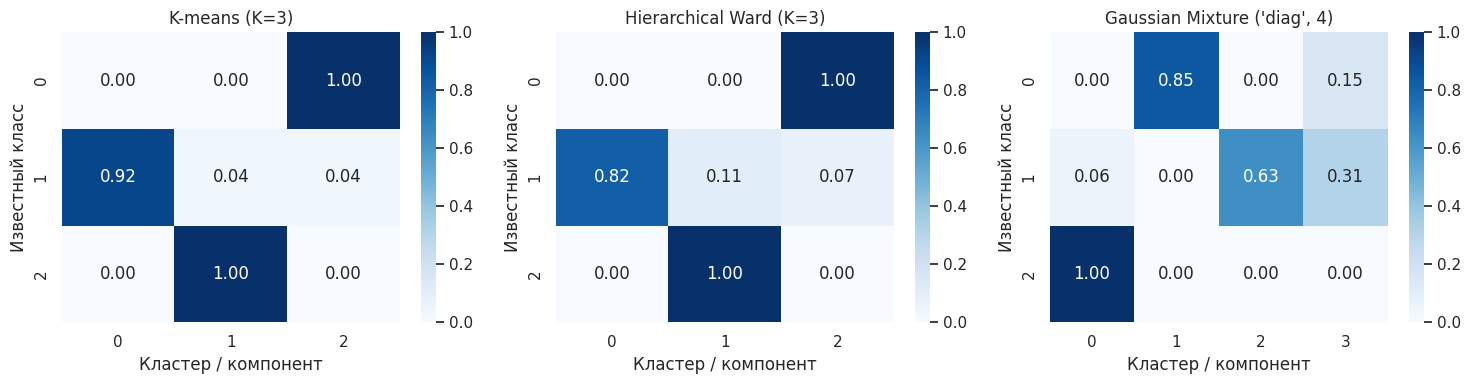

In [12]:
# 10. Внешняя диагностика: только здесь впервые анализируем y_hidden
# Кластеры уже построены без использования y_hidden; эти метки применяются только для оценки постфактум.
selected_labelings = {
    'K-means (K=3)': labels,
    'Hierarchical Ward (K=3)': hierarchical_labels['ward'],
    f'Gaussian Mixture {best_gmm_key}': gmm_labels,
}
# Включаем плотностные методы в диагностику только если разбиение содержит хотя бы два кластера без учёта шума.
for method_name, lab in [('DBSCAN selected', dbscan_labels_selected), ('HDBSCAN', hdbscan_labels)]:
    if lab is not None and len(set(lab) - {-1}) >= 2:
        selected_labelings[method_name] = lab

external_rows = []
contingency_tables = {}
for name, lab in selected_labelings.items():
    external_rows.append({
        'Модель': name,
        'ARI': adjusted_rand_score(y_hidden, lab),
        'NMI': normalized_mutual_info_score(y_hidden, lab),
        'Число назначенных меток (вкл. noise)': len(np.unique(lab)),
        'Доля noise': float(np.mean(lab == -1)) if np.any(np.asarray(lab) == -1) else 0.0,
    })
    contingency_tables[name] = pd.crosstab(y_hidden.rename('известный класс'),
                                            pd.Series(lab, index=X.index, name='кластер'))
external_metrics = pd.DataFrame(external_rows).set_index('Модель').sort_values('ARI', ascending=False)
display(external_metrics.round(4))

print('Contingency table для выбранного K-means (абсолютные количества):')
display(contingency_tables['K-means (K=3)'])
print('Та же таблица, нормированная по строкам известного класса:')
display(pd.crosstab(y_hidden.rename('известный класс'), pd.Series(labels, index=X.index, name='кластер'), normalize='index').round(3))

# Visual diagnostic: one row-normalized contingency heatmap per main model.
main_names = list(selected_labelings.keys())[:3]
fig, axes = plt.subplots(1, len(main_names), figsize=(5 * len(main_names), 4))
if len(main_names) == 1:
    axes = [axes]
for ax, name in zip(axes, main_names):
    table = pd.crosstab(y_hidden, selected_labelings[name], normalize='index')
    sns.heatmap(table, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, ax=ax)
    ax.set_title(name)
    ax.set_xlabel('Кластер / компонент')
    ax.set_ylabel('Известный класс')
plt.tight_layout()
plt.show()

**Вывод.** ARI и NMI теперь используются как внешняя диагностика: они сопоставляют полученные разбиения с известными классами, которые не участвовали в обучении и выборе параметров. ARI корректирует согласованность пар с учётом случайного совпадения, а NMI оценивает нормированную взаимную информацию; обе метрики не зависят от номеров кластеров. Contingency table показывает, насколько каждый известный класс распределяется по найденным сегментам и где наблюдается смешение. Эти оценки не доказывают, что метки класса — единственный правильный ответ для unsupervised-задачи: структура химических признаков может отражать другие закономерности. Если бы ARI использовался для подбора K, возникла бы утечка целевой информации и задача перестала бы быть честно неконтролируемой.

## 11. PCA против нелинейной карты

**Цель:** Научиться критически читать 2D-embedding.  
**Задание:** Сравнить PCA(2), t-SNE и, при доступности, UMAP. Для t-SNE проверить не менее трех perplexity и двух seed. Цветом показать одни и те же cluster labels. Не кластеризовать только по красивой картинке.  
**Ожидаемый результат:** Набор карт и список устойчивых/неустойчивых визуальных наблюдений.

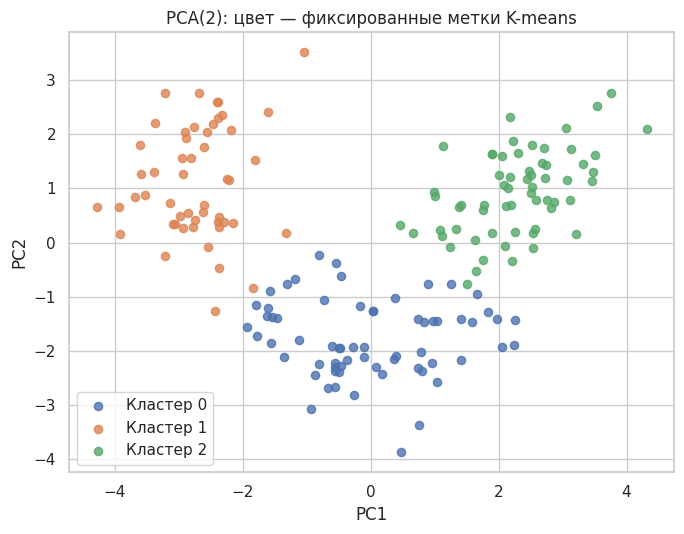

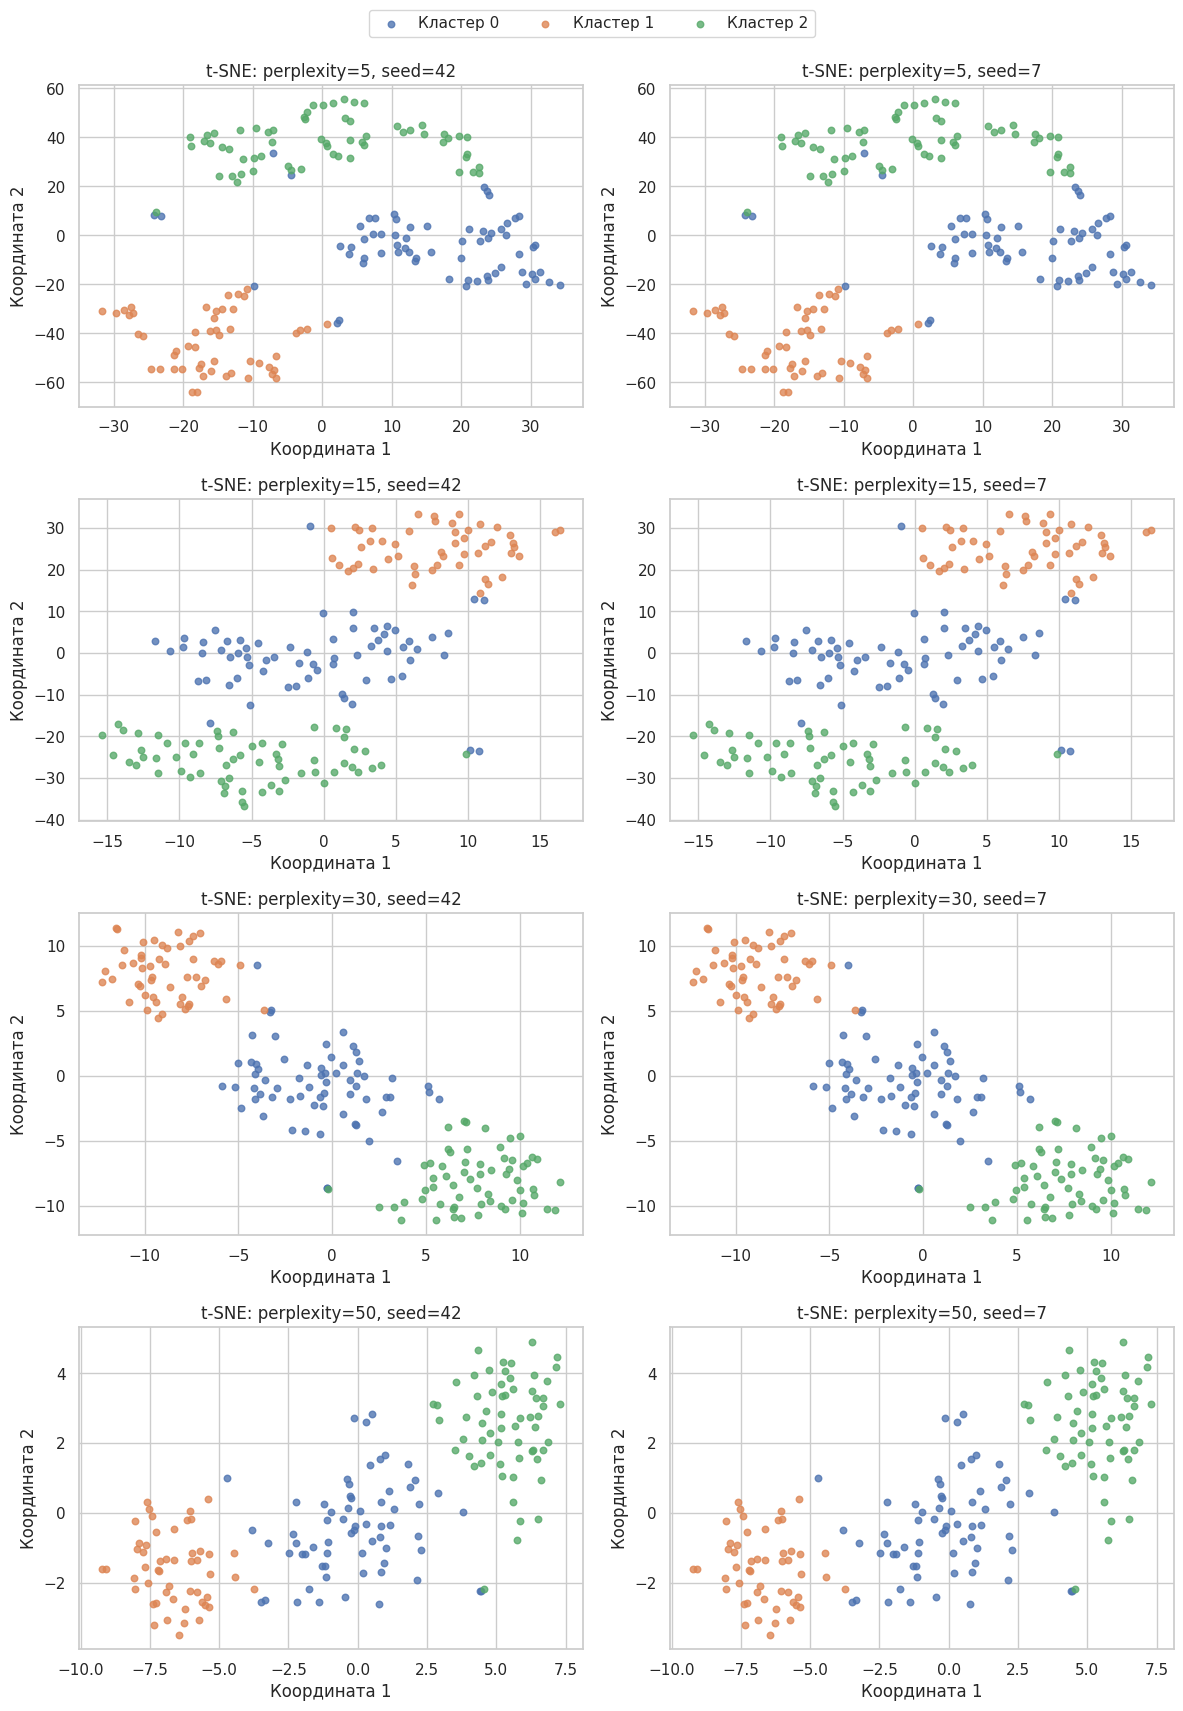

,perplexity,seed,trustworthiness@10
1,5,7,0.9423
0,5,42,0.9423
3,15,7,0.9563
2,15,42,0.9563
5,30,7,0.9562
4,30,42,0.9562
7,50,7,0.9545
6,50,42,0.9545


Trustworthiness оценивает сохранение локальных соседств относительно исходного пространства; координаты разных t-SNE запусков напрямую сравнивать нельзя из-за произвольных поворотов, сдвигов и масштабов.
UMAP не выполнен: пакет umap-learn отсутствует в текущем окружении. PCA и t-SNE сравнены без установки дополнительных пакетов.


In [13]:
# 11. Сравнение PCA(2), t-SNE и, если доступен, UMAP
# Один и тот же набор cluster labels K-means используется для окраски всех карт.
Z_pca2 = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Xs)

fig, ax = plt.subplots(figsize=(7, 5.5))
for cluster in sorted(np.unique(labels)):
    m = labels == cluster
    ax.scatter(Z_pca2[m, 0], Z_pca2[m, 1], label=f'Кластер {cluster}', alpha=.8, s=35)
ax.set(title='PCA(2): цвет — фиксированные метки K-means', xlabel='PC1', ylabel='PC2')
ax.legend()
plt.tight_layout()
plt.show()

perplexities = [5, 15, 30, 50]
seeds_tsne = [42, 7]
tsne_embeddings = {}
tsne_rows = []
fig, axes = plt.subplots(len(perplexities), len(seeds_tsne), figsize=(12, 17))
for i, perp in enumerate(perplexities):
    for j, seed in enumerate(seeds_tsne):
        tsne = TSNE(n_components=2, perplexity=perp, init='pca', learning_rate='auto',
                    random_state=seed, max_iter=1000)
        Z = tsne.fit_transform(Xs)
        tsne_embeddings[(perp, seed)] = Z
        for cluster in sorted(np.unique(labels)):
            m = labels == cluster
            axes[i, j].scatter(Z[m, 0], Z[m, 1], alpha=.78, s=22, label=f'Кластер {cluster}')
        axes[i, j].set_title(f't-SNE: perplexity={perp}, seed={seed}')
        axes[i, j].set_xlabel('Координата 1')
        axes[i, j].set_ylabel('Координата 2')
        score_trust = trustworthiness(Xs, Z, n_neighbors=10)
        tsne_rows.append({'perplexity': perp, 'seed': seed, 'trustworthiness@10': score_trust})
handles, legend_labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc='upper center', ncol=K_FINAL, bbox_to_anchor=(.5, 1.01))
plt.tight_layout(rect=[0, 0, 1, .985])
plt.show()
tsne_quality = pd.DataFrame(tsne_rows).sort_values(['perplexity', 'seed'])
display(tsne_quality.round(4))
print('Trustworthiness оценивает сохранение локальных соседств относительно исходного пространства; координаты разных t-SNE запусков напрямую сравнивать нельзя из-за произвольных поворотов, сдвигов и масштабов.')

# UMAP is optional; do not install packages or silently change the environment.
umap_available = importlib.util.find_spec('umap') is not None
if umap_available:
    import umap
    umap_model = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1,
                          random_state=RANDOM_STATE)
    Z_umap = umap_model.fit_transform(Xs)
    fig, ax = plt.subplots(figsize=(7, 5.5))
    for cluster in sorted(np.unique(labels)):
        m = labels == cluster
        ax.scatter(Z_umap[m, 0], Z_umap[m, 1], label=f'Кластер {cluster}', alpha=.8, s=35)
    ax.set(title='UMAP(2): цвет — фиксированные метки K-means', xlabel='UMAP1', ylabel='UMAP2')
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print('UMAP не выполнен: пакет umap-learn отсутствует в текущем окружении. PCA и t-SNE сравнены без установки дополнительных пакетов.')

**Вывод.** PCA(2) сохраняет глобальные направления наибольшей линейной дисперсии, тогда как t-SNE главным образом стремится сохранять локальные соседства и может сильно менять глобальную геометрию. Поэтому расстояния между далёкими визуальными группами и их относительные размеры на t-SNE-карте нельзя интерпретировать как точные расстояния в исходном пространстве. Проверка нескольких perplexity и двух seed демонстрирует чувствительность картинки к параметрам; trustworthiness помогает численно оценить сохранение локальных соседств. Цвет на всех картах соответствует одним и тем же уже вычисленным меткам K-means: embedding не используется для подбора этих меток. UMAP запускается только при наличии пакета; отсутствие пакета зафиксировано явно, вместо скрытой установки зависимости.

## 12. Итоговый model memo

**Цель:** Сформулировать решение, пригодное для обсуждения с заказчиком.  
**Задание:** Выбрать финальный pipeline. Описать цель, preprocessing, алгоритм, параметры, метрики, профили, устойчивость, правило для новых объектов, ограничения и мониторинг. Предложить один эксперимент для проверки полезности сегментов.  
**Ожидаемый результат:** Model memo до 2 страниц и итоговая таблица решений.

In [14]:
# 12. Итоговый model memo и проверка воспроизводимости
import numpy, pandas, sklearn
print('Версии библиотек:')
version_table = pd.DataFrame({
    'Пакет': ['Python', 'numpy', 'pandas', 'scikit-learn', 'scipy', 'matplotlib', 'seaborn'],
    'Версия': [sys.version.split()[0], numpy.__version__, pandas.__version__, sklearn.__version__,
               __import__('scipy').__version__, __import__('matplotlib').__version__, sns.__version__]
})
display(version_table)

# Final decision table, combining the principal internal scores and diagnostics.
final_decision_rows = []
km_row = kmeans_metrics.loc[K_FINAL]
final_decision_rows.append({
    'Модель': f'K-means, K={K_FINAL}', 'inertia': km_row['inertia'],
    'silhouette': km_row['silhouette'], 'Calinski–Harabasz': km_row['Calinski–Harabasz'],
    'Davies–Bouldin': km_row['Davies–Bouldin'],
    'Замечание': 'Основной вариант: простая интерпретация и прогноз новых объектов'
})
ward_row = hierarchical_metrics.loc['ward']
final_decision_rows.append({
    'Модель': 'Agglomerative Ward, K=3', 'inertia': np.nan,
    'silhouette': ward_row['silhouette'], 'Calinski–Harabasz': ward_row['Calinski–Harabasz'],
    'Davies–Bouldin': ward_row['Davies–Bouldin'],
    'Замечание': f"ARI vs K-means={ward_row['ARI vs K-means']:.3f}; нет естественного predict для новых точек в стандартном sklearn API"
})
final_decision_rows.append({
    'Модель': f'Gaussian Mixture {best_gmm_key}', 'inertia': np.nan,
    'silhouette': silhouette_score(Xs, gmm_labels),
    'Calinski–Harabasz': calinski_harabasz_score(Xs, gmm_labels),
    'Davies–Bouldin': davies_bouldin_score(Xs, gmm_labels),
    'Замечание': f"Лучшая BIC-модель: BIC={best_gmm_row['BIC']:.1f}; вероятностные назначения"
})
if len(set(dbscan_labels_selected) - {-1}) >= 2:
    mask_db = dbscan_labels_selected != -1
    db_sil_final = silhouette_score(Xs[mask_db], dbscan_labels_selected[mask_db]) if len(np.unique(dbscan_labels_selected[mask_db])) >= 2 else np.nan
    final_decision_rows.append({
        'Модель': f'DBSCAN eps={sel_key[0]}, min_samples={sel_key[1]}', 'inertia': np.nan,
        'silhouette': db_sil_final, 'Calinski–Harabasz': np.nan, 'Davies–Bouldin': np.nan,
        'Замечание': f"{int(len(set(dbscan_labels_selected)-{-1}))} кластеров, шум={np.mean(dbscan_labels_selected==-1):.1%}"
    })
final_decision_table = pd.DataFrame(final_decision_rows).set_index('Модель')
display(final_decision_table.round(4))

# Summarize stability for the chosen K=3.
chosen_bootstrap_ari = ari_df[(ari_df['K'] == K_FINAL) & (ari_df['оценка'] == 'Bootstrap')]['ARI']
chosen_seed_ari = ari_df[(ari_df['K'] == K_FINAL) & (ari_df['оценка'] == 'Разные инициализации')]['ARI']
print(f'Для K={K_FINAL}: median ARI между seed-разбиениями = {chosen_seed_ari.median():.3f}; median bootstrap ARI = {chosen_bootstrap_ari.median():.3f}.')
print(f'Профилирование: размеры кластеров = {cluster_sizes.to_dict()}; пороги PCA 80/90/95% = {[int(np.searchsorted(cum, t)+1) for t in (.80,.90,.95)]} компонент.')

Версии библиотек:


,Пакет,Версия
0,Python,3.13.5
1,numpy,2.3.5
2,pandas,2.2.3
3,scikit-learn,1.8.0
4,scipy,1.17.0
5,matplotlib,3.10.8
6,seaborn,0.13.2


,inertia,silhouette,Calinski–Harabasz,Davies–Bouldin,Замечание
Модель,,,,,
"K-means, K=3",1277.9285,0.2849,70.9400,1.3892,Основной вариант: простая интерпретация и прог...
"Agglomerative Ward, K=3",NaN,0.2774,67.6475,1.4186,ARI vs K-means=0.853; нет естественного predic...
"Gaussian Mixture ('diag', 4)",NaN,0.2401,52.8751,1.8740,Лучшая BIC-модель: BIC=5476.5; вероятностные н...
"DBSCAN eps=2.2, min_samples=10",NaN,0.3940,NaN,NaN,"2 кластеров, шум=50.0%"


Для K=3: median ARI между seed-разбиениями = 0.964; median bootstrap ARI = 0.913.
Профилирование: размеры кластеров = {0: 65, 1: 51, 2: 62}; пороги PCA 80/90/95% = [5, 8, 10] компонент.


**Вывод.** Для основного pipeline оставлен `StandardScaler` + `KMeans(K=3, n_init=50, random_state=42)`: он даёт назначение новому объекту через ближайший центроид, а центроиды и профили можно регулярно проверять. Это рабочий исследовательский выбор, а не универсально лучшая модель: иерархическая кластеризация задаёт альтернативную геометрию, GMM даёт мягкую неопределённость, а плотностные методы полезны только там, где структура действительно проявляется в плотности. Итоговую модель следует принимать в прикладной процесс только после проверки устойчивости, осмысленности профилей и пользы сегментов на независимых данных. Для мониторинга нужны доли сегментов, расстояния новых объектов до центроидов, изменение распределений признаков и периодическая переоценка стабильности; если профиль данных заметно дрейфует, требуется повторное обучение и повторная валидация.

## Итоговый model memo

**Цель и единица анализа.** Сгруппировать образцы вина по сходству 13 химических измерений; один объект — один образец. Кластеры рассматриваются как разведочные профили, не как метки качества или происхождения.

**Pipeline и выбранное решение.** Для основной модели используется `StandardScaler`, затем `KMeans(n_clusters=3, n_init=50, random_state=42)`. Масштабирование необходимо, чтобы расстояния не определялись только исходными единицами измерения. При выборе K рассмотрены inertia, silhouette, Calinski–Harabasz и Davies–Bouldin; K=2 и K=4 сохранены как альтернативы в анализе устойчивости. Иерархические методы, DBSCAN/HDBSCAN и Gaussian Mixture сравниваются как другие геометрические предположения, а PCA/t-SNE используются только для визуализации.

**Интерпретация и неопределённость.** Профили описываются медианами, IQR и standardized lift; типичный образец — ближайший к центроиду, пограничные — те, у которых близки расстояния до двух центроидов. Для GMM используются posterior probability и энтропия. Внешние ARI/NMI и таблицы сопряжённости рассчитываются только после фиксации unsupervised-разбиений и служат диагностикой, а не критерием обучения.

**Назначение новых объектов.** Сохранять обученный scaler и центроиды; для каждого нового наблюдения проверять схему и единицы измерения, применять тот же `scaler.transform`, затем `kmeans.predict`. Не переобучать scaler отдельно на новых данных. Вместе с меткой сохранять расстояние до назначенного центроида; необычно большое расстояние помечать для проверки, не выдавая его автоматически за аномалию.

**Ограничения и мониторинг.** Набор небольшой и учебный, период измерений не указан, а кластеризация чувствительна к признакам, масштабу, алгоритму и параметрам. Раз в период отслеживать доли кластеров, распределения входных признаков, расстояния до центроидов и появление пограничных наблюдений; при сдвиге распределения переоценивать scaler и модель на новой обучающей выборке с повторной проверкой устойчивости. Не интерпретировать сегменты как причинные категории и не переносить их на другую популяцию без валидации.

**Эксперимент для проверки пользы.** На независимой выборке новых образцов применить зафиксированный pipeline и провести слепую экспертную/сенсорную оценку либо измерить заранее определённый прикладной результат. До анализа задать критерий полезности сегментов и сравнить, добавляют ли cluster-профили информацию сверх общей модели по химическим признакам. Если сегменты не дают воспроизводимого улучшения принятия решений, не внедрять кластеризацию в процесс.

## Краткие ответы на контрольные вопросы

1. **Почему scaling — часть модели близости?** Евклидовы расстояния зависят от единиц и дисперсий признаков, поэтому scaler меняет геометрию пространства и само определение похожести.
2. **Как внутренняя метрика может противоречить прикладной полезности?** Метрика оценивает геометрию и компактность, но не учитывает стоимость ошибок, удобство действий или независимый бизнес-результат.
3. **Почему номера кластеров нельзя сравнивать напрямую?** Перестановка номеров не меняет разбиение; нужно сопоставлять назначения метриками вроде ARI или таблицами пересечений.
4. **Как отличить плотностный шум от бизнес-аномалии?** DBSCAN/HDBSCAN определяют редкость относительно локальной плотности, тогда как бизнес-аномалия требует предметного контекста и проверки последствий.
5. **Почему 2D t-SNE/UMAP не доказывает число кластеров?** Встраивание искажает глобальные расстояния и зависит от параметров; визуальная группа может быть артефактом проекции.
6. **Как назначать новые объекты и обнаруживать drift?** Для K-means используют зафиксированные scaler и центроиды; отслеживают расстояния, доли кластеров и дрейф распределений входных признаков.
7. **Чем explained variance отличается от полезной информации?** Дисперсия отражает вариативность признаков, а полезность зависит от конкретного решения и требуемого результата; низкодисперсионный сигнал тоже может быть важен.